# Keras
Librería para programar redes neuronales de una manera más sencilla que con TensorFlow. Keras se encuentra en una capa de abstracción por encima de TensorFlow.

[Documentación](https://keras.io/guides/)

In [ ]:
#!pip install tensorflow --upgrade
#!pip install keras --upgrade

Defaulting to user installation because normal site-packages is not writeable
  Using cached tensorflow-2.22.0rc1-cp314-cp314-win_amd64.whl.metadata (4.6 kB)
Using cached tensorflow-2.22.0rc1-cp314-cp314-win_amd64.whl (382.7 MB)



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ----------------- ---------------------- 1.0/2.4 MB 5.8 MB/s eta 0:00:01
   ---------------------------------------  2.4/2.4 MB 5.7 MB/s eta 0:00:01
   ---------------------------------------- 2.4/2.4 MB 5.3 MB/s  0:00:00



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
#!python.exe -m pip install --upgrade pip

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   --------------------- ------------------ 1.0/2.0 MB 5.1 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 5.1 MB/s  0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 26.2.2
    Uninstalling pip-26.2.2:
      Successfully uninstalled pip-26.2.2


Empezamos importando librerías

In [5]:
# import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import pandas as pd
import numpy as np

Cargamos los datos de mnist. No vamos a tratar imagenes con redes convolucionales (perdemos la estructura espacial 2D). Todos los pixeles se convertirán en un vector de 28x28 features independientes, que serán las entradas del modelo.

In [6]:
# Cogemos las imágenes de los dígitos asi como el conjunto de train y test
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

Vemos dimensiones del dataset

In [7]:
'''
60.000 imagenes de 28x28 pixeles
'''
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [8]:
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

In [9]:
2**8

256

60.000 imágenes de 28x28 pixeles. Vamos a representar una de ellas

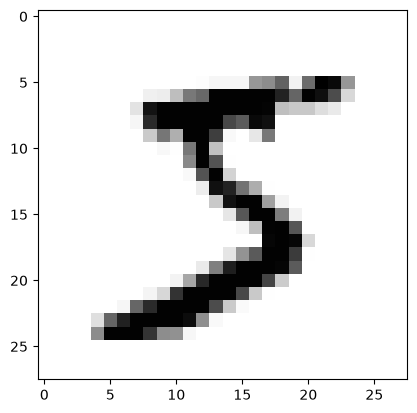

In [10]:
import matplotlib.pyplot as plt

plt.imshow(X_train[0], cmap=plt.get_cmap('Greys'));

Cada imagen se compone de 28x28 pixeles, y cada pixel representa una escala de grises que va del 0 al 255. Siendo 0 el blanco y 255 negro.

¿Se te ocurre alguna manera de normalizar los datos?

In [11]:
np.max(X_train)

np.uint8(255)

In [12]:
0/255

0.0

In [13]:
128/255

0.5019607843137255

In [14]:
255/255

1.0

In [15]:
X_train = X_train.astype("float32")/255
X_test = X_test.astype("float32")/255

In [16]:
np.mean(X_train)

np.float32(0.13066047)

In [17]:
'''
Comprobamos la normalización
'''
X_train[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [18]:
y_train = y_train.astype("float32")
y_test = y_test.astype("float32")

Guardamos datos para validación. Estos datos se usarán durante el entrenamiento. Otra opción es decirle a keras en la etapa de entrenamiento que reserve un X % de los datos para validar.

In [19]:
X_val = X_train[-10000:]
y_val = y_train[-10000:]

X_train = X_train[:-10000]
y_train = y_train[:-10000]

In [20]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(50000, 28, 28)
(10000, 28, 28)
(10000, 28, 28)


Montamos la arquitectura de la red neuronal. Se va a componer de:
* **Sequential**: API para iniciar la red neuronal. No cuenta como capa.
* **Flatten**: capa de entrada. Necesita un vector unidimensional. Como tenemos imágenes, esta capa aplana las imagenes (2D) en 1D.
* **Dense**: es una hidden layer. Se compondrá de `n` neuronas y de una función de activación que se aplicará a todas las neuronas de la capa.

Recuerda que es un problema de clasificación multiclase (10 clases) y que por tanto la última capa se compondrá de tantas neuronas como clases tengas.

En cuanto a las funciones de activación es recomendable usar relu en las hidden layer, que tarda menos en entrenar, mientras que la ultima (output) suele ser una softmax.

In [21]:
28*28

784

In [22]:
X_train.shape

(50000, 28, 28)

In [23]:
28*28

784

In [24]:
model = keras.models.Sequential()

# Capa entrada
#model.add(keras.layers.Flatten(input_shape=(28, 28)))

model.add(keras.layers.Input(shape=((28, 28))))


# Hidden layer
model.add(keras.layers.Dense(units = 300,
                            activation='relu'))

# Hidden layer
model.add(keras.layers.Dense(units = 100,
                            activation='relu'))

# Capa salida
model.add(keras.layers.Dense(units = 10,
                            activation='softmax'))

In [25]:
# Otra manera de declarar la red neuronal
capas = [
    #keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(units = 300, activation='relu'),
    keras.layers.Dense(units = 100, activation='relu'),
    keras.layers.Dense(units = 10, activation='softmax')
]

model = keras.models.Sequential(capas)

Podemos ver las capas, y acceder a sus elementos

In [26]:
print(model.layers[0])

<Flatten name=flatten, built=True>


Podemos ver los pesos de las capas sin entrenar, porque los inicializa aleatoriamente. Los bias los inicializa a 0.

In [27]:
hidden1 = model.layers[1]
weights, biases = hidden1.get_weights()

In [28]:
weights

array([[-0.01268567,  0.04696132,  0.04219076, ...,  0.04577514,
        -0.05000672, -0.04143781],
       [-0.01579382,  0.06202382, -0.01298125, ..., -0.04012437,
         0.05390522,  0.06452501],
       [ 0.05186187, -0.07335708, -0.01204778, ..., -0.03124257,
         0.0017534 ,  0.02477881],
       ...,
       [-0.00706743,  0.0589605 ,  0.01191738, ...,  0.02312995,
         0.04377993, -0.00380805],
       [-0.07120822, -0.04221909, -0.01630715, ..., -0.03439611,
        -0.00663158, -0.00499815],
       [-0.02410312,  0.04057213, -0.02121921, ..., -0.06795733,
        -0.01423864, -0.02960081]], shape=(784, 300), dtype=float32)

In [29]:
len(weights)

784

In [30]:
len(weights[0])

300

In [31]:
28*28

784

In [32]:
300*784

235200

In [33]:
weights.size

235200

In [34]:
len(biases)

300

Establecemos la configuración de ejecución... el compile.

In [35]:
model.compile(
    optimizer = keras.optimizers.SGD(),
    loss = keras.losses.SparseCategoricalCrossentropy(),
    metrics = [keras.metrics.SparseCategoricalAccuracy()]
)

In [36]:
# Equivalente
model.compile(
    optimizer = "sgd",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [37]:
# Summary
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

In [38]:
784 * 300 + 300

235500

In [39]:
# 1º neurona de la 1º hidden layer
# y = a + w1*x1 + w2*x2 + .... wn*xn
# a es el intercepto llamado bias
# wn es cada uno de los pesos que va a ir actualizando con el backpropagation
# n es 784
# En la 1º hidden layer tenemos 784 pesos por cada neurona, al tener 300, tenemos un total de:
print(784*300 + 300)

235500


In [40]:
300 * 784 + 300

235500

In [41]:
300 * 100 + 100

30100

In [42]:
100 * 10 + 10

1010

Entrenamos el modelo. Usamos los datos de entrenamiento. El batch_size es la cantidad de muestras que utiliza el SGD, y las epochs son las iteraciones que realiza en el entrenamiento.

In [43]:
X_train.shape

(50000, 28, 28)

In [44]:
40000/128

312.5

In [45]:
history = model.fit(
    X_train,
    y_train,
    batch_size = 128,
    epochs = 50,
    validation_data = (X_val, y_val) # validation_split = 0.1
)

Epoch 1/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7074 - loss: 1.2169 - val_accuracy: 0.8684 - val_loss: 0.5830
Epoch 2/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8689 - loss: 0.5088 - val_accuracy: 0.8954 - val_loss: 0.3927
Epoch 3/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8906 - loss: 0.3984 - val_accuracy: 0.9084 - val_loss: 0.3351
Epoch 4/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9014 - loss: 0.3514 - val_accuracy: 0.9157 - val_loss: 0.3056
Epoch 5/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9093 - loss: 0.3229 - val_accuracy: 0.9184 - val_loss: 0.2864
Epoch 6/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9148 - loss: 0.3021 - val_accuracy: 0.9252 - val_loss: 0.2700
Epoch 7/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9190 - loss: 0.2851 - val_accuracy: 0.9266 - val_loss: 0.2584
Epoch 8/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9228 - loss: 0.2707 - val_accuracy: 0.

Podemos reentrenar el modelo. No empieza de nuevo, sino que retoma el entrenamiento anterior.

In [46]:
model.fit(
    X_train,
    y_train,
    batch_size = 64,
    epochs = 10,
    validation_data = (X_val, y_val) # validation_split = 0.1
)

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9773 - loss: 0.0812 - val_accuracy: 0.9716 - val_loss: 0.1043
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9784 - loss: 0.0780 - val_accuracy: 0.9711 - val_loss: 0.1025
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9787 - loss: 0.0754 - val_accuracy: 0.9718 - val_loss: 0.1015
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9800 - loss: 0.0723 - val_accuracy: 0.9716 - val_loss: 0.1028
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9807 - loss: 0.0701 - val_accuracy: 0.9700 - val_loss: 0.1042
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9815 - loss: 0.0675 - val_accuracy: 0.9723 - val_loss: 0.0995
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9823 - loss: 0.0650 - val_accuracy: 0.9722 - val_loss: 0.0966
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9830 - loss: 0.0627 - val_accuracy: 0.

Veamos el histórico del entrenamiento, para poder representarlo posteriormente.

In [47]:
# print(history.params)
# print(history.epoch)
print(history.history)

{'accuracy': [0.7073799967765808, 0.8689000010490417, 0.8906000256538391, 0.9014400243759155, 0.909280002117157, 0.9147599935531616, 0.9190400242805481, 0.9228399991989136, 0.9269400238990784, 0.9301599860191345, 0.9330999851226807, 0.9363399744033813, 0.9379400014877319, 0.9407399892807007, 0.9419199824333191, 0.9445000290870667, 0.9463000297546387, 0.9478999972343445, 0.9496600031852722, 0.9514600038528442, 0.9530199766159058, 0.9543600082397461, 0.9557200074195862, 0.9571200013160706, 0.958299994468689, 0.9598399996757507, 0.9611799716949463, 0.9617599844932556, 0.9631999731063843, 0.9642400145530701, 0.9647200107574463, 0.9659600257873535, 0.9671599864959717, 0.9678800106048584, 0.9687399864196777, 0.9698200225830078, 0.9702799916267395, 0.9710000157356262, 0.9716200232505798, 0.9725199937820435, 0.9725800156593323, 0.9737600088119507, 0.9739599823951721, 0.97461998462677, 0.9751799702644348, 0.9753999710083008, 0.9761599898338318, 0.9767199754714966, 0.9771000146865845, 0.97747999

In [48]:
history.history

{'accuracy': [0.7073799967765808,
  0.8689000010490417,
  0.8906000256538391,
  0.9014400243759155,
  0.909280002117157,
  0.9147599935531616,
  0.9190400242805481,
  0.9228399991989136,
  0.9269400238990784,
  0.9301599860191345,
  0.9330999851226807,
  0.9363399744033813,
  0.9379400014877319,
  0.9407399892807007,
  0.9419199824333191,
  0.9445000290870667,
  0.9463000297546387,
  0.9478999972343445,
  0.9496600031852722,
  0.9514600038528442,
  0.9530199766159058,
  0.9543600082397461,
  0.9557200074195862,
  0.9571200013160706,
  0.958299994468689,
  0.9598399996757507,
  0.9611799716949463,
  0.9617599844932556,
  0.9631999731063843,
  0.9642400145530701,
  0.9647200107574463,
  0.9659600257873535,
  0.9671599864959717,
  0.9678800106048584,
  0.9687399864196777,
  0.9698200225830078,
  0.9702799916267395,
  0.9710000157356262,
  0.9716200232505798,
  0.9725199937820435,
  0.9725800156593323,
  0.9737600088119507,
  0.9739599823951721,
  0.97461998462677,
  0.9751799702644348,
  

In [49]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [50]:
pd.DataFrame(history.history)

,accuracy,loss,val_accuracy,val_loss
0,0.70738,1.216926,0.8684,0.582965
1,0.86890,0.508806,0.8954,0.392716
2,0.89060,0.398353,0.9084,0.335089
3,0.90144,0.351403,0.9157,0.305587
4,0.90928,0.322920,0.9184,0.286354
5,0.91476,0.302108,0.9252,0.270042
6,0.91904,0.285068,0.9266,0.258416
7,0.92284,0.270715,0.9304,0.246085
8,0.92694,0.258086,0.9352,0.235864
9,0.93016,0.246637,0.9373,0.225870


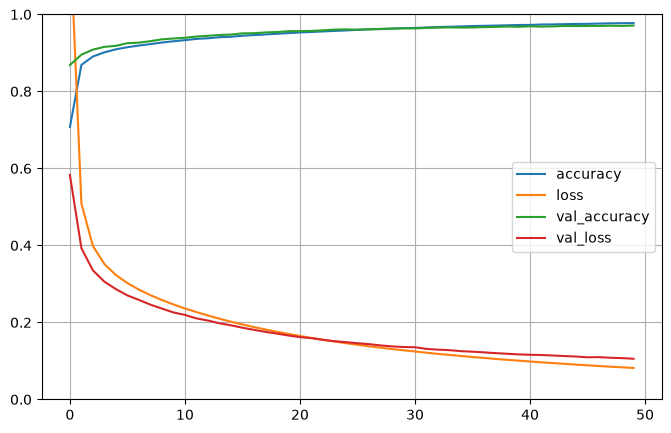

In [51]:
import pandas as pd
import matplotlib.pyplot as plt

pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1) # set the vertical range to [0-1]
plt.show()

Si el modelo no ha ido bien, prueba a cambiar el learning rate, cambia de optimizador y después prueba a cambiar capas, neuronas y funciones de activación.

Ya tenemos el modelo entrenado. Probémoslo con test

In [52]:
results = model.evaluate(X_test, y_test)
results

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9734 - loss: 0.0868


[0.08683471381664276, 0.9733999967575073]

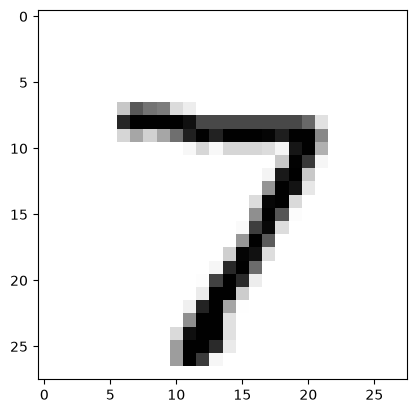

In [53]:
# Cogemos el primero
plt.imshow(X_test[0].reshape(28,28), cmap=plt.get_cmap('Greys'));

In [54]:
X_test[:1]

array([[[0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.

In [55]:
predictions = model.predict(X_test[:1])
print(predictions.shape)
np.round(predictions,3)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
(1, 10)


array([[0.   , 0.   , 0.   , 0.001, 0.   , 0.   , 0.   , 0.998, 0.   ,
        0.   ]], dtype=float32)

In [56]:
predictions.argmax()

np.int64(7)

In [57]:
X_test.shape[0]

10000

In [58]:
X_test.shape[0]/32

312.5

In [59]:
model.predict(X_test).argmax(axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

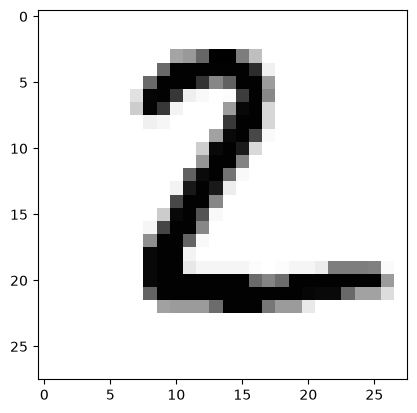

In [60]:
plt.imshow(X_test[1].reshape(28,28), cmap=plt.get_cmap('Greys'));

In [61]:
from sklearn.metrics import confusion_matrix, classification_report

confusion_matrix(y_test, model.predict(X_test).argmax(axis=1))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


array([[ 968,    0,    0,    0,    1,    1,    5,    1,    4,    0],
       [   0, 1125,    3,    0,    0,    1,    3,    0,    3,    0],
       [   6,    2, 1010,    1,    2,    0,    2,    5,    4,    0],
       [   0,    0,    9,  978,    0,    9,    0,    6,    6,    2],
       [   2,    0,    3,    1,  955,    1,    5,    2,    2,   11],
       [   5,    1,    0,   11,    1,  860,    9,    1,    3,    1],
       [   5,    3,    0,    1,    3,    3,  941,    0,    2,    0],
       [   0,    8,   12,    4,    0,    1,    0,  997,    1,    5],
       [   3,    1,    3,    8,    3,    5,    7,    4,  940,    0],
       [   6,    6,    2,    8,   13,    2,    1,    8,    3,  960]])

In [62]:
print(classification_report(y_test, model.predict(X_test).argmax(axis=1)))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

         0.0       0.97      0.99      0.98       980
         1.0       0.98      0.99      0.99      1135
         2.0       0.97      0.98      0.97      1032
         3.0       0.97      0.97      0.97      1010
         4.0       0.98      0.97      0.97       982
         5.0       0.97      0.96      0.97       892
         6.0       0.97      0.98      0.97       958
         7.0       0.97      0.97      0.97      1028
         8.0       0.97      0.97      0.97       974
         9.0       0.98      0.95      0.97      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



### Problema de regresión
Veamos un ejemplo de cómo aplicar una red neuronal de TensorFlow a un problema de regresión.

In [63]:
# Cargamos datos
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()
df = pd.DataFrame(housing.data, columns = housing.feature_names)
df['target'] = housing['target']
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Divimos en train, test y validation

In [64]:
X_train_full, X_test, y_train_full, y_test = train_test_split(housing.data,
                                                              housing.target)

X_train, X_valid, y_train, y_valid = train_test_split(X_train_full,
                                                      y_train_full)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)
X_test = scaler.transform(X_test)

In [65]:
X_train.shape

(11610, 8)

Montamos el modelo. Simplemente se compondrá de una hidden layer, a la que le configuramos una capa previa de entrada de 8 neuronas (las features).

Se trata de un modelo de regresión, por lo que la capa de salida es una única neurona.

In [66]:
11610/32

362.8125

In [67]:
X_train.shape[1:]

(8,)

In [68]:
model = keras.models.Sequential([
    keras.layers.Input(shape=X_train.shape[1:]),
    keras.layers.Dense(30, activation = 'relu'),
                      #input_shape = X_train.shape[1:]),
    keras.layers.Dense(1)
])

model.compile(loss = "mean_squared_error",
             optimizer = "sgd")

history = model.fit(X_train,
                   y_train,
                   epochs = 20,
                   validation_data = (X_valid, y_valid))

Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.5810 - val_loss: 0.5933
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.5095 - val_loss: 0.5028
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4561 - val_loss: 0.4802
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4397 - val_loss: 0.4563
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4255 - val_loss: 0.4474
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4281 - val_loss: 0.5234
Epoch 7/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4171 - val_loss: 0.4361
Epoch 8/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4006 - val_loss: 0.4322
Epoch 9/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3953 - val_loss: 0.4258
Epoch 10/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3916 - val_loss: 0.4634
Epoch 11/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4332 - val_loss: 0.4158
Epoch 12/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

In [69]:
8*30 + 30

270

In [70]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 30)             │           270 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 303 (1.19 KB)

 Trainable params: 301 (1.18 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [71]:
mse_test = model.evaluate(X_test, y_test)
print(mse_test)

162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3677
0.3676826059818268


In [72]:
y_pred = model.predict(X_test[:5])
y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


array([[2.356862 ],
       [1.0372498],
       [2.5429645],
       [0.642955 ],
       [2.4015818]], dtype=float32)

### Guardar modelo
Para guardar el modelo, en el formato de Keras. 

In [73]:
model.save("my_keras_model.keras")

In [74]:
# Lo volvemos a cargar
model = keras.models.load_model("my_keras_model.keras")

### Callbacks
Son funciones predefinidas de Keras a aplicar durante el entrenamiento
Por ejemplo, `ModelCheckpoint` sirve para que el modelo se vaya guardando tras cada epoch. Así no perdemos el progreso en caso de que decidamos interrumpir el entrenamiento. El callback recibe como argumento el nombre del objeto donde queremos que se guarde el modelo entrenado.

In [75]:
checkpoint_cb = keras.callbacks.ModelCheckpoint("callback_model.keras")
history = model.fit(X_train,
                   y_train,
                   epochs=30,
                   callbacks = [checkpoint_cb])

Epoch 1/30
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3668
Epoch 2/30
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3651
Epoch 3/30
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3636
Epoch 4/30
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3626
Epoch 5/30
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3598
Epoch 6/30
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3588
Epoch 7/30
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3599
Epoch 8/30
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3567
Epoch 9/30
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3550
Epoch 10/30
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3531
Epoch 11/30
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3548
Epoch 12/30
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3538
Epoch 13/30
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3501
Epoch 14/30
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3492
Epoch 15/30
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - lo

### Early Stopping
Interrumpe el entrenamiento cuando no ve progreso en el set de validación. Para ello tiene en cuenta un numero de epochs llamado `patience`. Se puede combinar con el callback

In [76]:
early_stopping_cb = keras.callbacks.EarlyStopping(patience=3)
history = model.fit(X_train,
                   y_train,
                   epochs=50,
                   validation_data = (X_valid, y_valid),
                   callbacks = [early_stopping_cb, checkpoint_cb])

Epoch 1/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3410 - val_loss: 0.3582
Epoch 2/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3365 - val_loss: 0.3882
Epoch 3/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3429 - val_loss: 0.3574
Epoch 4/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3331 - val_loss: 0.3562
Epoch 5/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3332 - val_loss: 0.3540
Epoch 6/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3310 - val_loss: 0.3533
Epoch 7/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3326 - val_loss: 0.3547
Epoch 8/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3351 - val_loss: 0.3507
Epoch 9/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3332 - val_loss: 0.3549
Epoch 10/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3340 - val_loss: 0.3542
Epoch 11/50
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3296 - val_loss: 0.3519
